# VGG16 + probly auf einem Bild

Sehr einfaches Beispiel: Wir nehmen das bekannte Bildnetz **VGG16**, lassen es ein Foto klassifizieren und fragen mit **probly**, **wie sicher** es sich dabei ist.

| Abschnitt | Inhalt |
|---|---|
| 1 | Imports |
| 2 | VGG16 laden |
| 3 | Bild laden und vorbereiten |
| 4 | Normale Vorhersage (ohne probly) |
| 5 | probly: Dropout-Modell und Unsicherheit |
| 6 | Vergleich: Foto gegen verrauschtes Foto gegen reines Rauschen |
| 7 | Zusammenfassung |

## 1. Imports

In [3]:
%pip install torch torchvision pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.models import vgg16, VGG16_Weights

from probly.method import dropout
from probly.representer import representer
from probly.quantification import quantify

torch.manual_seed(0)

- `torchvision` enthält VGG16 und die zugehörigen Vorverarbeitungsschritte
- `PIL` lädt das Bild, `matplotlib` zeigt es an
- `dropout`, `representer`, `quantify` sind wieder die drei probly-Bausteine: Modell umbauen, viele Vorhersagen holen, Unsicherheit berechnen

## 2. VGG16 laden
Wir benutzen ein **bereits trainiertes** VGG16 (auf ImageNet, 1000 Klassen wie „Hund", „Katze", „Auto"). Wir müssen es also nicht selbst trainieren.

In [4]:
gewichte = VGG16_Weights.IMAGENET1K_V1
vgg = vgg16(weights=gewichte)
vgg.eval()                                  # Vorhersagemodus

klassen = gewichte.meta["categories"]       # die 1000 Klassennamen
print("Anzahl Klassen:", len(klassen))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /Users/tristanfuchs/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:26<00:00, 21.3MB/s] 


Anzahl Klassen: 1000


- `vgg16(weights=...)` lädt das Netz mit fertigen Gewichten. Beim ersten Mal wird es heruntergeladen (etwa 500 MB).
- `vgg.eval()` schaltet in den Vorhersagemodus.
- VGG16 besteht aus 13 Faltungsschichten und 3 vollverbundenen Schichten. Es gibt für ein Bild 1000 Zahlen aus (Logits), eine pro Klasse.
- In den vollverbundenen Schichten hat VGG16 schon **Dropout-Schichten** (`nn.Dropout`). Das nutzen wir in Abschnitt 5.

## 3. Bild laden und vorbereiten
Du kannst ein eigenes Bild benutzen: lege es als `bild.jpg` neben das Notebook. Gibt es keins, laden wir ein Beispielfoto (einen Hund) herunter.

findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


Form der Eingabe: (1, 3, 224, 224)


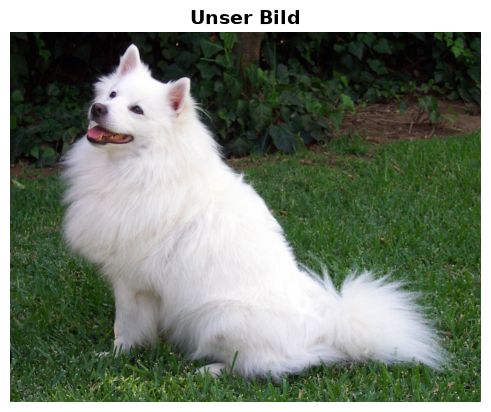

In [5]:
pfad = "bild.jpg"
if not os.path.exists(pfad):
    urllib.request.urlretrieve("https://github.com/pytorch/hub/raw/master/images/dog.jpg", pfad)

bild = Image.open(pfad).convert("RGB")
vorverarbeitung = gewichte.transforms()          # Größe 224x224 + Normalisierung
x = vorverarbeitung(bild).unsqueeze(0)           # Form (1, 3, 224, 224)

print("Form der Eingabe:", tuple(x.shape))
plt.imshow(bild); plt.axis("off"); plt.title("Unser Bild"); plt.show()

VGG16 erwartet Bilder in einem bestimmten Format:
- `transforms()` skaliert das Bild auf 224 × 224 Pixel und normalisiert die Farben genau so, wie das Netz damals trainiert wurde
- `unsqueeze(0)` fügt eine „Bild-Achse" hinzu: Form (1, 3, 224, 224) = 1 Bild, 3 Farbkanäle, 224 × 224 Pixel

## 4. Normale Vorhersage (ohne probly)
Zuerst machen wir es so, wie man es normalerweise tut: Bild rein, Klasse raus.

In [6]:
with torch.no_grad():
    logits = vgg(x)
wahrsch = torch.softmax(logits, dim=1)[0]

top5 = torch.topk(wahrsch, 5)
for p, i in zip(top5.values, top5.indices):
    print(f"{klassen[i]:30s} {p.item():.3f}")

Samoyed                        0.840
Pomeranian                     0.033
Eskimo dog                     0.017
white wolf                     0.016
Great Pyrenees                 0.012


- `softmax` macht aus den 1000 Logits Wahrscheinlichkeiten, die zusammen 1 ergeben
- `topk(5)` nimmt die 5 wahrscheinlichsten Klassen

Das Netz nennt eine Klasse mit einer Wahrscheinlichkeit. **Wie verlässlich** diese Zahl ist, sagt es nicht. Genau das macht probly möglich.

## 5. probly: Dropout-Modell und Unsicherheit
Wir bauen VGG16 mit probly zu einem **MC-Dropout-Modell** um. Dann geht dasselbe Bild mehrfach durch das Netz, jedes Mal mit anderem Dropout, und wir sehen, wie stark die Antworten schwanken.

In [7]:
mc  = dropout(vgg, p=0.2, predictor_type="logit_classifier")
rep = representer(mc, num_samples=20)         # 20 Durchläufe pro Bild

with torch.no_grad():
    sample = rep.represent(x)

mittel = sample.sample_mean().probabilities.detach()[0]
unsicher = quantify(sample).total.detach().numpy()[0]

top5 = torch.topk(mittel, 5)
print("Mittlere Vorhersage über 20 Durchläufe:")
for p, i in zip(top5.values, top5.indices):
    print(f"  {klassen[i]:30s} {p.item():.3f}")
print(f"\nGesamt-Unsicherheit: {unsicher:.5f}")

Mittlere Vorhersage über 20 Durchläufe:
  Samoyed                        0.745
  Eskimo dog                     0.034
  Pomeranian                     0.029
  Great Pyrenees                 0.022
  Siberian husky                 0.013

Gesamt-Unsicherheit: 1.55799


Was hier passiert:
- `dropout(vgg, p=0.2, ...)` kopiert das Netz und fügt Dropout-Schichten ein. Das Original `vgg` bleibt unverändert.
- `representer(mc, num_samples=20)` schickt jedes Bild 20-mal durch das Netz. Dropout ist dabei automatisch **angeschaltet**.
- `sample_mean()` mittelt die 20 Antworten. Das ist die Vorhersage.
- `quantify(sample).total` misst, **wie stark die 20 Antworten schwanken**. Das ist die Gesamt-Unsicherheit: klein = die Durchläufe sind sich einig, groß = sie widersprechen sich.

Die Zahl allein sagt noch wenig. Sie wird erst im nächsten Abschnitt aussagekräftig, wenn wir sie mit anderen Bildern vergleichen.

## 6. Vergleich: Foto, verrauschtes Foto, reines Rauschen
Wir füttern das Netz mit drei Bildern, die immer „unbekannter" werden, und schauen, ob die Unsicherheit steigt.

Bild               Klasse                            P  Unsicherheit
Originalfoto       Samoyed                       0.802       1.23412
Stark verrauscht   sea cucumber                  0.162       3.74810
Reines Rauschen    jellyfish                     0.076       4.85494


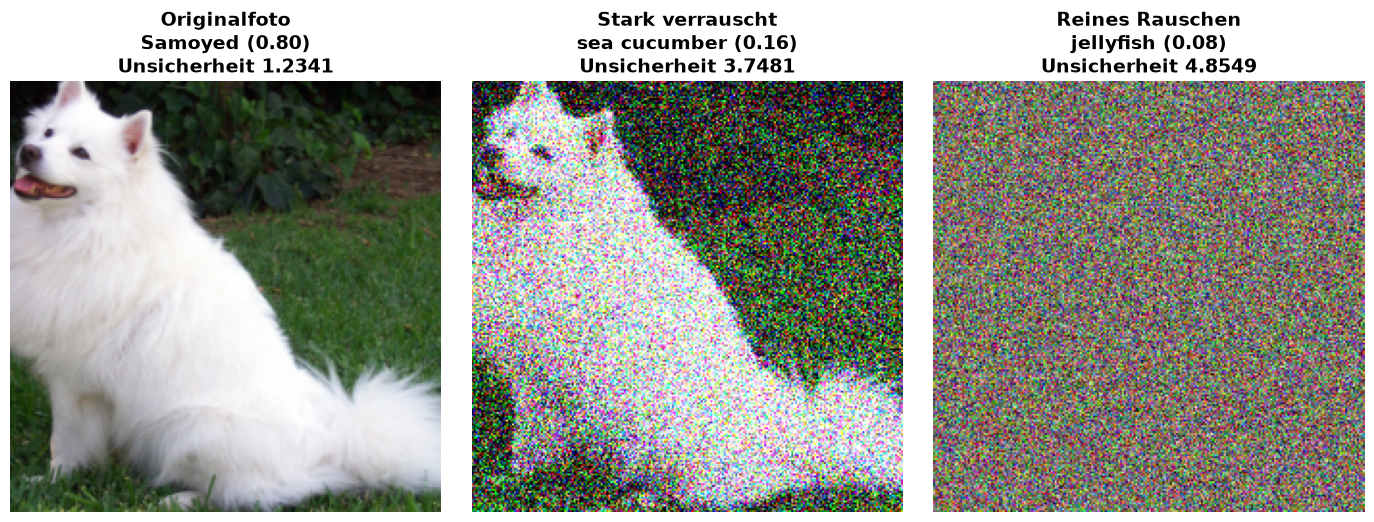

In [8]:
bilder = {
    "Originalfoto":      x,
    "Stark verrauscht":  x + 1.5 * torch.randn_like(x),
    "Reines Rauschen":   torch.randn(1, 3, 224, 224),
}

mittel_n = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std_n    = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
def zum_anzeigen(t):
    # Normalisierung rückgängig machen, damit man das Bild sehen kann
    a = t[0].numpy() * std_n + mittel_n
    return np.clip(a.transpose(1, 2, 0), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
print(f"{'Bild':18s} {'Klasse':28s} {'P':>6s}  {'Unsicherheit':>12s}")
for ax, (name, bild_t) in zip(axes, bilder.items()):
    with torch.no_grad():
        s = rep.represent(bild_t)
    p = s.sample_mean().probabilities.detach()[0]
    u = quantify(s).total.detach().numpy()[0]
    top = int(p.argmax())
    print(f"{name:18s} {klassen[top]:28s} {p[top].item():6.3f}  {u:12.5f}")
    ax.imshow(zum_anzeigen(bild_t)); ax.axis("off")
    ax.set_title(f"{name}\n{klassen[top]} ({p[top].item():.2f})\nUnsicherheit {u:.4f}")
plt.tight_layout(); plt.show()

**So liest man das Ergebnis:**
- **Originalfoto:** Das Netz kennt solche Bilder. Die Unsicherheit sollte klein sein.
- **Stark verrauscht:** Das Bild ist beschädigt. Das Netz wird unsicherer, die Unsicherheit sollte steigen.
- **Reines Rauschen:** Das Netz hat so etwas nie gesehen. Es nennt trotzdem irgendeine Klasse, aber die Unsicherheit sollte hier am höchsten sein.

Das ist der Kern von probly: Auch wenn das Netz bei Unsinn selbstbewusst eine Klasse ausgibt, zeigt die Unsicherheit, dass man dem Ergebnis nicht trauen sollte. Die genauen Zahlen hängen vom Bild ab, achte vor allem auf die **Reihenfolge** der Unsicherheiten.

## 7. Zusammenfassung
- **VGG16** ist ein fertiges, vortrainiertes Bildnetz. Es gibt eine Klasse und eine Wahrscheinlichkeit aus, aber keine Aussage darüber, wie verlässlich das ist.
- **probly** baut daraus mit `dropout(...)` ein Modell, das dasselbe Bild mehrfach mit anderem Dropout bewertet.
- Die **Streuung** dieser Bewertungen (`quantify(...).total`) ist die Unsicherheit: klein bei bekannten Bildern, größer bei beschädigten oder fremden.

**Nächste Schritte zum Ausprobieren:** eigenes Bild als `bild.jpg` speichern, `num_samples` erhöhen (z. B. 50), `p` ändern (z. B. 0.5) oder ein Bild nehmen, das keine der 1000 Klassen zeigt (z. B. ein Diagramm).






Bild               Top-Klasse                    Ø P     Std    Min    Max  probly total
Originalfoto       Samoyed                     0.841  0.1229  0.594  0.979       1.48726
Stark verrauscht   coral reef                  0.168  0.1223  0.021  0.455       3.98334


findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


Reines Rauschen    jellyfish                   0.095  0.1179  0.005  0.482       4.59717


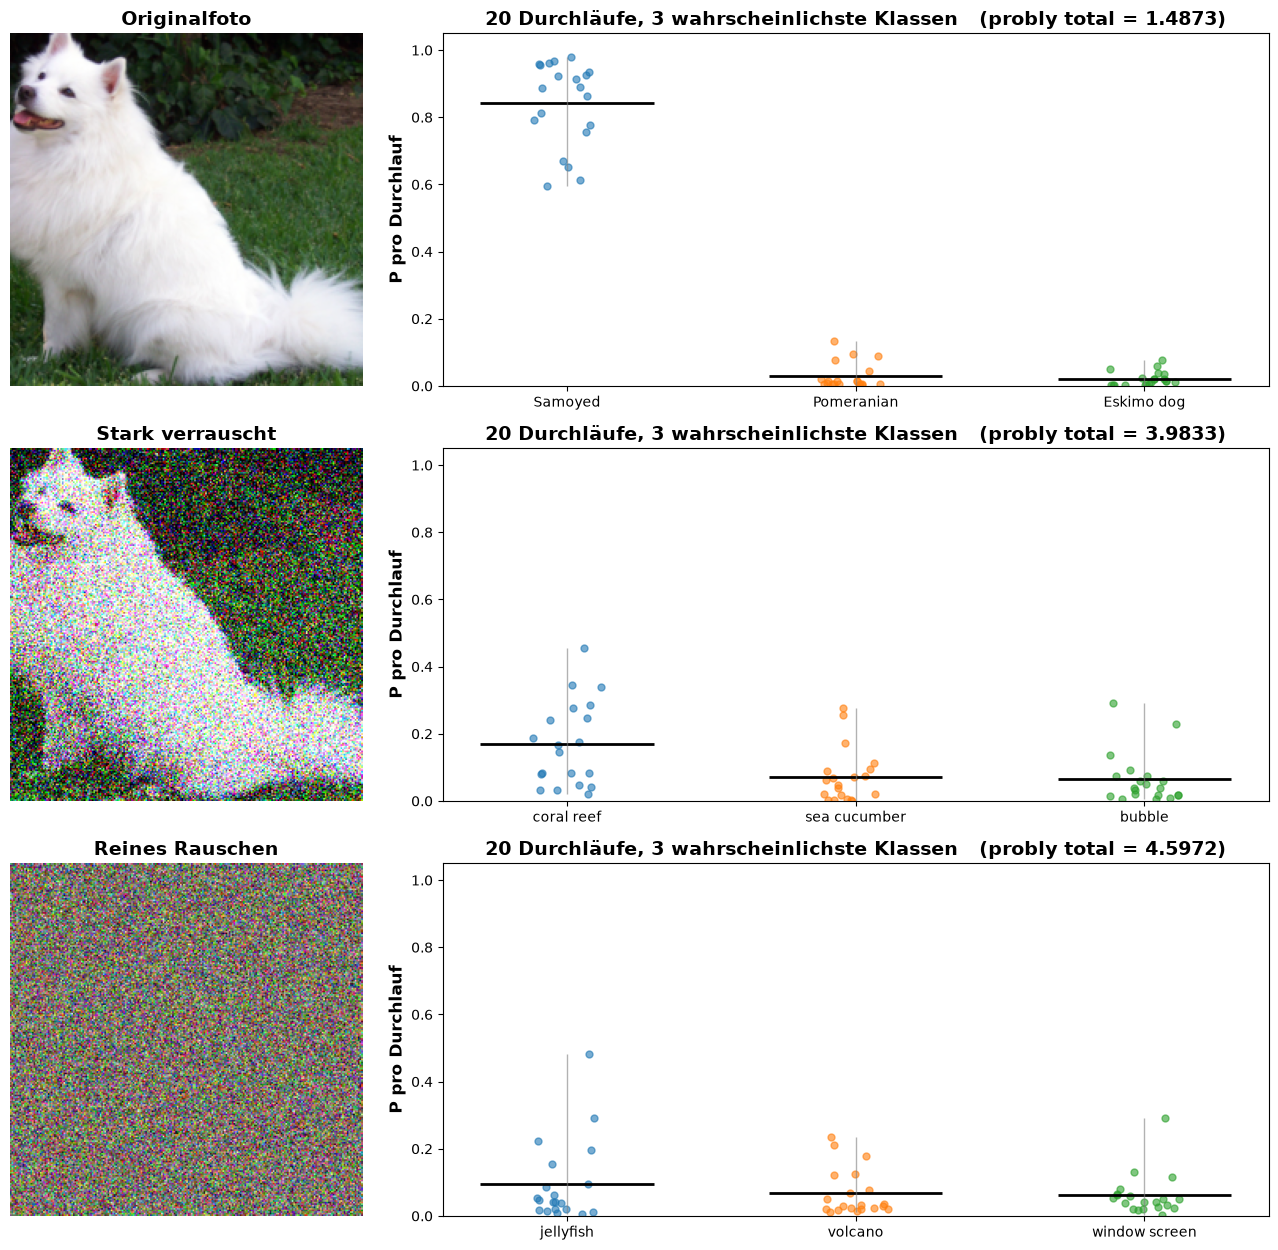

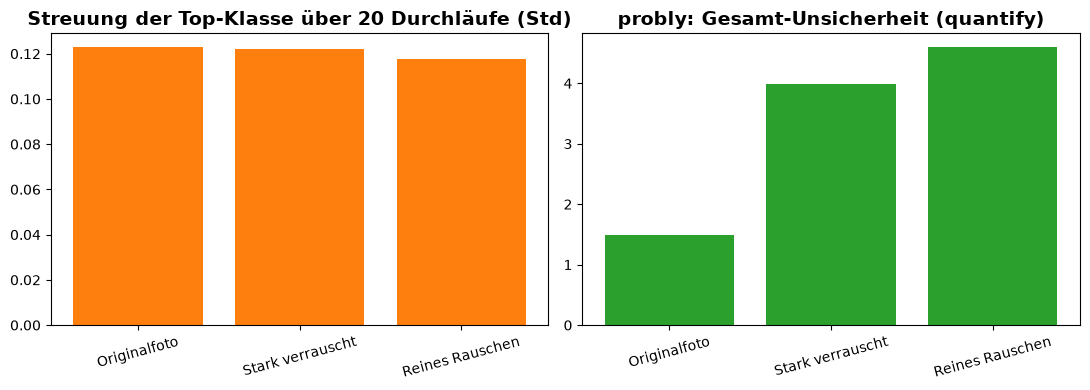

In [9]:
# ============================================================
# 8. Wie entsteht die Unsicherheit? Die Einzeldurchläufe sichtbar machen
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import torch
from probly.representer import representer
from probly.quantification import quantify

N_DURCH = 20
rep1 = representer(mc, num_samples=1)      # liefert genau EINE Dropout-Vorhersage pro Aufruf

def einzel_vorhersagen(bild_t):
    # 20 Durchläufe nacheinander, jeder mit anderem Dropout -> Form (20, 1000)
    ps = []
    with torch.no_grad():
        for _ in range(N_DURCH):
            ps.append(rep1.represent(bild_t).sample_mean().probabilities.detach()[0])
    return torch.stack(ps).numpy()

# ---------------- Zahlen + Grafik 1: Streuung der einzelnen Durchläufe ----------------
fig, axes = plt.subplots(len(bilder), 2, figsize=(13, 4.2 * len(bilder)),
                         gridspec_kw={"width_ratios": [1, 2.2]})
ergebnisse = {}
print(f"{'Bild':18s} {'Top-Klasse':26s} {'Ø P':>6s} {'Std':>7s} {'Min':>6s} {'Max':>6s} {'probly total':>13s}")

for zeile, (name, bild_t) in enumerate(bilder.items()):
    einzel = einzel_vorhersagen(bild_t)                         # (20, 1000)
    mittel = einzel.mean(0)
    top3 = np.argsort(mittel)[::-1][:3]                         # 3 wahrscheinlichste Klassen
    with torch.no_grad():
        total = quantify(rep.represent(bild_t)).total.detach().numpy()[0]
    ergebnisse[name] = (einzel[:, top3[0]].std(), total)

    k = top3[0]
    print(f"{name:18s} {klassen[k]:26s} {mittel[k]:6.3f} {einzel[:, k].std():7.4f} "
          f"{einzel[:, k].min():6.3f} {einzel[:, k].max():6.3f} {total:13.5f}")

    # linke Spalte: das Bild
    axes[zeile, 0].imshow(zum_anzeigen(bild_t)); axes[zeile, 0].axis("off")
    axes[zeile, 0].set_title(name)

    # rechte Spalte: jeder Punkt = ein Dropout-Durchlauf
    ax = axes[zeile, 1]
    for pos, kl in enumerate(top3):
        werte = einzel[:, kl]
        ax.scatter(np.full(N_DURCH, pos) + np.random.uniform(-0.12, 0.12, N_DURCH), werte,
                   alpha=0.6, s=25)
        ax.hlines(werte.mean(), pos - 0.3, pos + 0.3, color="k", lw=2)       # Mittelwert
        ax.vlines(pos, werte.min(), werte.max(), color="gray", lw=1, alpha=0.6)  # Spannweite
    ax.set_xticks(range(3), [klassen[kl][:18] for kl in top3])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("P pro Durchlauf")
    ax.set_title(f"20 Durchläufe, 3 wahrscheinlichste Klassen   (probly total = {total:.4f})")
plt.tight_layout(); plt.show()

# ---------------- Grafik 2: Streuung gegen probly-Unsicherheit ----------------
namen = list(ergebnisse)
streuung = [ergebnisse[n][0] for n in namen]
totale   = [ergebnisse[n][1] for n in namen]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(namen, streuung, color="tab:orange")
axes[0].set_title("Streuung der Top-Klasse über 20 Durchläufe (Std)")
axes[1].bar(namen, totale, color="tab:green")
axes[1].set_title("probly: Gesamt-Unsicherheit (quantify)")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------------------

SHAPIQ

In [29]:
# ============================================================
# 1. Imports (SSL-Fix für den Mac, falls Downloads fehlschlagen)
# ============================================================
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.models import vgg16, VGG16_Weights
import shapiq

In [37]:
# ============================================================
# 2. VGG16 und Bild laden
# ============================================================
gewichte = VGG16_Weights.IMAGENET1K_V1
vgg = vgg16(weights=gewichte).eval()
klassen = gewichte.meta["categories"]

pfad = "andrew-s-ouo1hbizWwo-unsplash-scaled.jpg"
if not os.path.exists(pfad):
    urllib.request.urlretrieve("https://github.com/pytorch/hub/raw/master/images/dog.jpg", pfad)

bild = Image.open(pfad).convert("RGB")
x = gewichte.transforms()(bild).unsqueeze(0)          # Form (1, 3, 224, 224)

# Klasse, die wir erklären wollen: die wahrscheinlichste
with torch.no_grad():
    wahrsch = torch.softmax(vgg(x), dim=1)[0]
ziel = int(wahrsch.argmax())
print(f"Zu erklärende Klasse: {klassen[ziel]}  (P = {wahrsch[ziel]:.3f})")

Zu erklärende Klasse: Border collie  (P = 0.084)


Bild wird geladen 

Vortrainierte Gewichte werden gewählt und mit .eval() in den Vorhersage modes geschalten 
Klassen ist die Liste der tausend klassennamen  

Bild wird geladen und vorbereteit, da RGB gebraucht wird und auf 224 x 224 Pixel gebracht

-with torch.no_grad() schaltet die Gradientenberechnung ab. Wir trainieren nichts, das spart Speicher und Zeit.
-vgg(x) gibt 1000 Rohwerte (Logits) aus.
-softmax macht daraus Wahrscheinlichkeiten, die zusammen 1 ergeben.
-[0] nimmt das erste (und einzige) Bild aus dem Stapel. wahrsch hat dann die Form (1000,).

argmax() gibt die Nummer der Klasse mit der höchsten Wahrscheinlichkeit zurück. Das ist die Klasse, die das Netz am wahrscheinlichsten findet.

In [38]:
# ============================================================
# 3. Bild in Felder (Spieler) aufteilen: 3 x 3 = 9 Felder
# ============================================================
N = 3
grenzen = np.linspace(0, 224, N + 1).astype(int)
feld_masken = []                                       # pro Feld eine 224x224-Maske
for r in range(N):
    for c in range(N):
        m = torch.zeros(224, 224)
        m[grenzen[r]:grenzen[r + 1], grenzen[c]:grenzen[c + 1]] = 1
        feld_masken.append(m)
feld_masken = torch.stack(feld_masken)                 # Form (9, 224, 224)
n_spieler = N * N

N = 3 ist die Zahl der Felder pro Zeile und Spalte. linspace(0, 224, 4) erzeugt 4 gleichmäßig verteilte Zahlen zwischen 0 und 224, und .astype(int) rundet sie ab:

[0, 74, 149, 224]

Das sind die Schnittlinien. Feld 1 reicht von Pixel 0 bis 74, Feld 2 von 74 bis 149, Feld 3 von 149 bis 224. 224 lässt sich nicht glatt durch 3 teilen, deshalb sind die Felder minimal verschieden groß (74, 75, 75 Pixel). Das stört nicht.

Die zwei Schleifen gehen alle Felder durch, r ist die Zeile und c die Spalte (also 3 × 3 = 9 Durchgänge).

Pro Feld wird eine Maske gebaut, ein 224 × 224 großes Raster aus Nullen. Mit der Zeile m[...] = 1 wird nur der Bereich dieses Feldes auf 1 gesetzt. Für das Feld oben links sieht das so aus:

1 1 0 0 0 0
1 1 0 0 0 0      (vereinfacht dargestellt, in echt 224 × 224)
0 0 0 0 0 0

Die Masken werden in der Reihenfolge gesammelt: oben links, oben Mitte, oben rechts, Mitte links usw. Diese Reihenfolge ist später wichtig, weil Spieler 0 das Feld oben links ist und Spieler 8 das Feld unten rechts.

In [39]:
# ============================================================
# 4. Das "Spiel": Wie sicher ist VGG16, wenn nur bestimmte Felder sichtbar sind?
# ============================================================
def spiel(koalitionen, batch=32):
    # koalitionen: (Anzahl, 9) mit True = Feld sichtbar, False = Feld grau (Mittelwert)
    ergebnisse = []
    k = torch.tensor(koalitionen, dtype=torch.float32)
    for start in range(0, len(k), batch):
        teil = k[start:start + batch]
        maske = (teil[:, :, None, None] * feld_masken[None]).sum(1)   # (B, 224, 224)
        bilder = x * maske[:, None]                                    # 0 = Mittelfarbe nach Normalisierung
        with torch.no_grad():
            p = torch.softmax(vgg(bilder), dim=1)[:, ziel]
        ergebnisse.append(p.numpy())
    return np.concatenate(ergebnisse).astype(float)

Diese Funktion ist das „Spiel“, das shapiq braucht. Sie bekommt Kombinationen von sichtbaren Bildfeldern und gibt zurück, wie sicher VGG16 die Zielklasse erkennt, wenn nur diese Felder zu sehen sind.

Eingabe und Ausgabe

Eingabe koalitionen: Eine Tabelle mit der Form (Anzahl, 9). Jede Zeile ist eine Kombination von Feldern (eine „Koalition“), True heißt „Feld sichtbar“, False heißt „Feld ausgeblendet“. Zum Beispiel sind in [True, False, False, True, ...] Feld 0 und Feld 3 sichtbar.
Ausgabe: Pro Zeile eine Zahl, nämlich die Wahrscheinlichkeit der Zielklasse für dieses teilweise sichtbare Bild.

Das ist derselbe Aufbau wie bei der Preisgeld-Funktion in Tristan_01 und bei den Modellfunktionen für Two Moons.

In [40]:
# ============================================================
# 5. shapiq: Beitrag jedes Feldes (Shapley-Werte)
# ============================================================
rechner = shapiq.ExactComputer(game=spiel, n_players=n_spieler)   # 2^9 = 512 Kombinationen (dauert etwas)
sv = rechner(index="SV", order=1)

werte = np.array([sv.dict_values.get((i,), 0.0) for i in range(n_spieler)])
basis = sv.dict_values.get((), 0.0)

print("\nShapley-Werte pro Feld (3x3, Zeilen oben nach unten):")
print(np.round(werte.reshape(N, N), 4))
print(f"\nBasis (alles grau):        {basis:.4f}")
print(f"Summe der Beiträge:        {werte.sum():.4f}")
print(f"Basis + Summe:             {basis + werte.sum():.4f}")
print(f"Vorhersage ganzes Bild:    {wahrsch[ziel]:.4f}")


Shapley-Werte pro Feld (3x3, Zeilen oben nach unten):
[[-0.1058 -0.0193  0.0267]
 [-0.0865 -0.0201  0.1786]
 [-0.0177 -0.0153  0.1428]]

Basis (alles grau):        0.0003
Summe der Beiträge:        0.0832
Basis + Summe:             0.0835
Vorhersage ganzes Bild:    0.0835


Dieser Teil lässt shapiq die Beiträge der 9 Felder berechnen und gibt sie als Zahlen aus. Am Ende prüft er, ob alles aufgeht.

ExactComputer probiert alle möglichen Kombinationen durch (bei 9 Feldern sind das 2⁹ = 512) und ruft dafür unsere Funktion spiel auf. Das ist die Zeit, die VGG16 braucht, deshalb dauert die Zelle.
index="SV" bedeutet: normale Shapley-Werte. Jedes Feld bekommt einen fairen Anteil an der Gesamtvorhersage.
order=1 heißt: nur einzelne Felder betrachten, keine Paare.

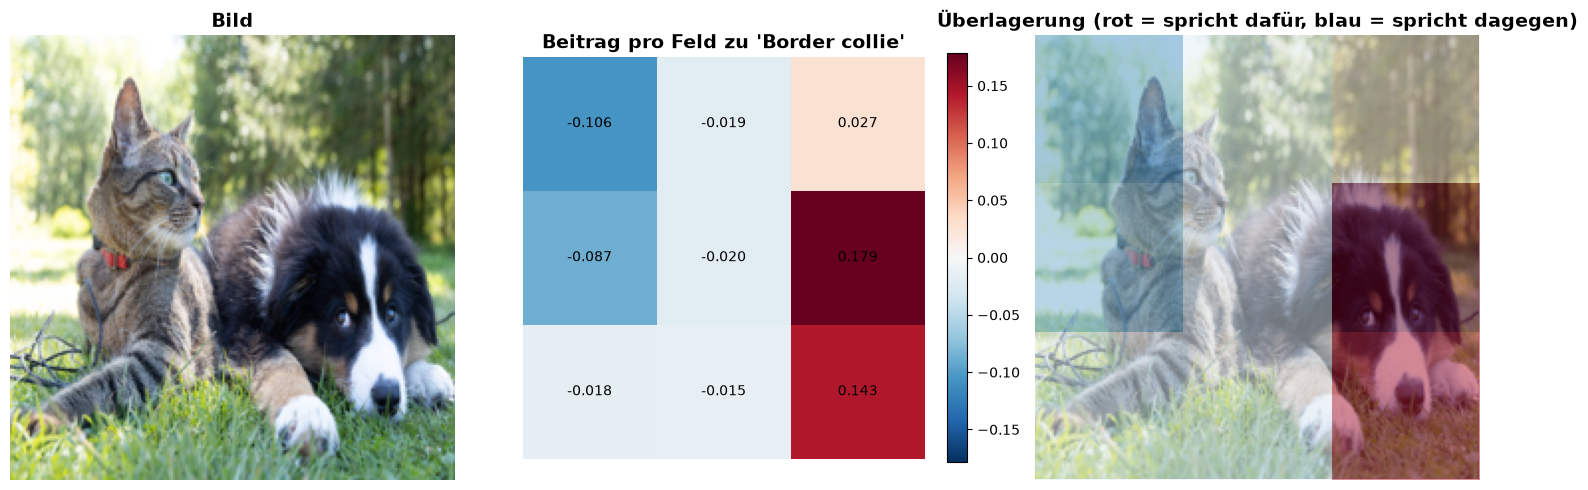

In [41]:
# ============================================================
# 6. Grafik: Bild, Beiträge, Überlagerung
# ============================================================
karte = werte.reshape(N, N)
g = np.abs(karte).max()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(bild.resize((224, 224))); axes[0].set_title("Bild"); axes[0].axis("off")

im = axes[1].imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g)
for r in range(N):
    for c in range(N):
        axes[1].text(c, r, f"{karte[r, c]:.3f}", ha="center", va="center")
axes[1].set_title(f"Beitrag pro Feld zu '{klassen[ziel]}'"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)

axes[2].imshow(bild.resize((224, 224)))
axes[2].imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g, alpha=0.5, extent=(0, 224, 224, 0), interpolation="nearest")
axes[2].set_title("Überlagerung (rot = spricht dafür, blau = spricht dagegen)"); axes[2].axis("off")
plt.tight_layout(); plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------------------


VERBINDUNG VON SHAPIQ UND PROBLY MIT VGG 16

Als Netz wird ein VGG 16 Netz benutzt welches 5 durchgengen wird mit dropout (20%)

Zielklasse: Border collie

=== Beitrag der Felder zur WAHRSCHEINLICHKEIT der Klasse (3x3) ===
[[-0.091  -0.0173  0.0236]
 [-0.0744 -0.0186  0.1725]
 [-0.0303 -0.0126  0.1319]]
Basis 0.0003 + Summe 0.0839 = 0.0842   (ganzes Bild: 0.0842)

=== Beitrag der Felder zur probly-UNSICHERHEIT (3x3) ===
[[-0.30903 -0.11667 -0.13046]
 [-0.53948  0.00064  0.21111]
 [-0.58691 -0.27897  0.26172]]
Basis 5.94442 + Summe -1.48805 = 4.45636   (ganzes Bild: 4.45636)


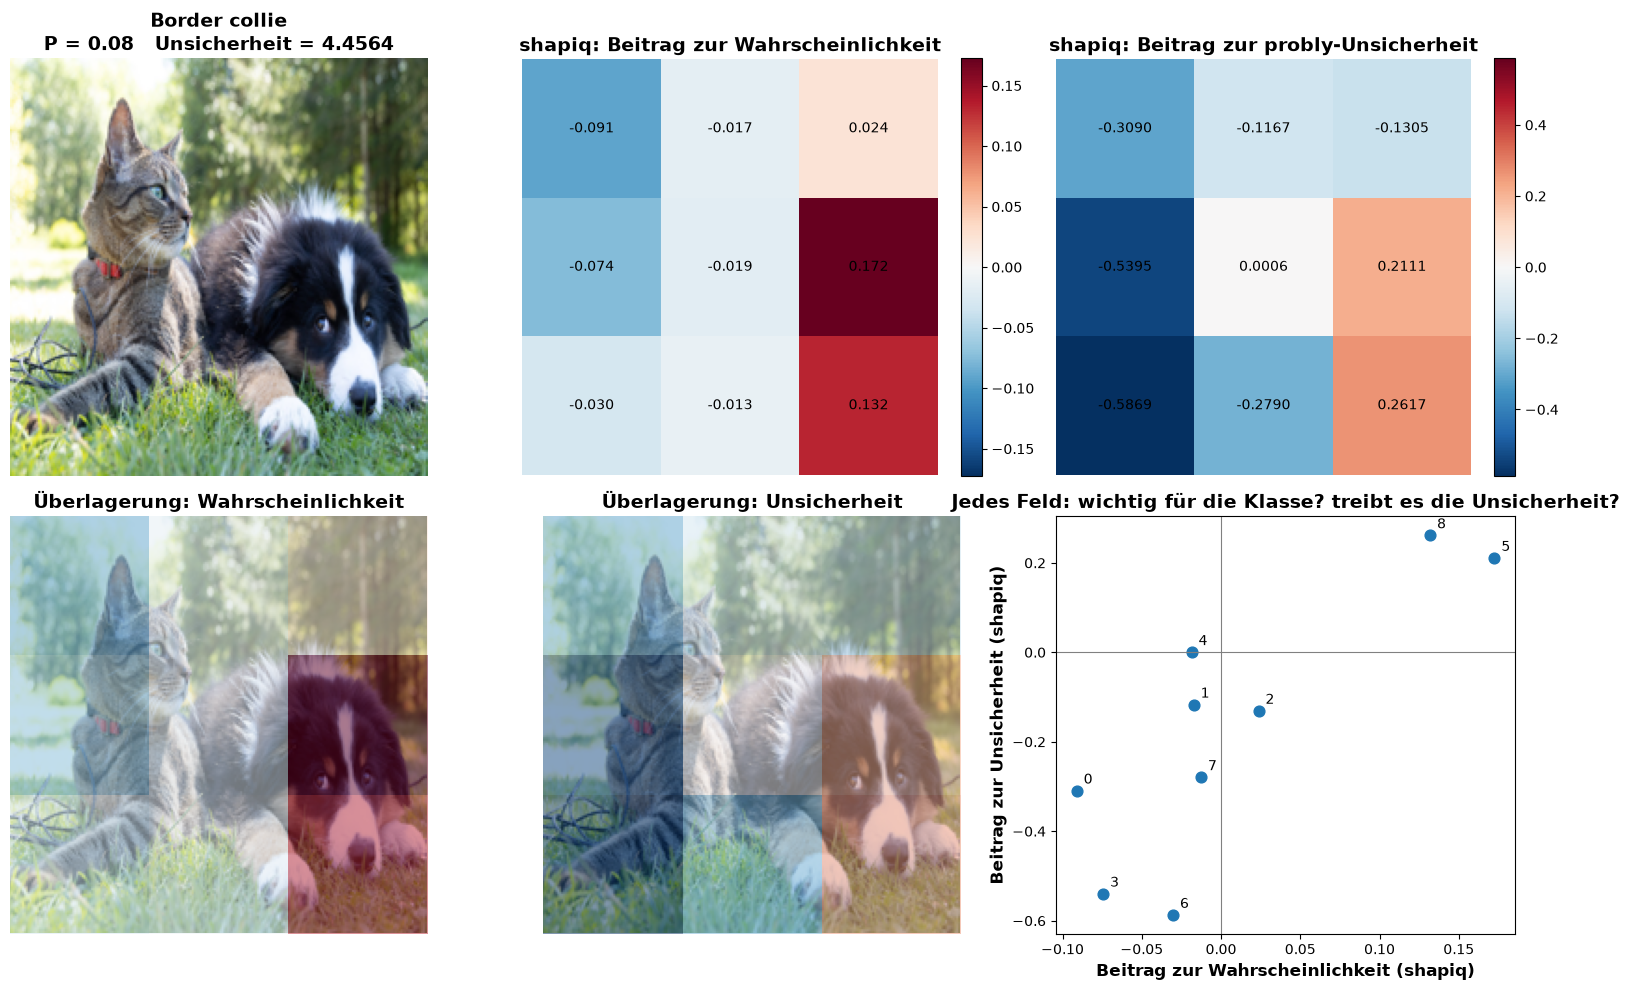


=== AUSWERTUNG ===
Wichtigstes Feld für die Klasse:        Feld 5  (+0.1725)
Feld mit größtem Beitrag zur Unsicherheit: Feld 8  (+0.26172)
Korrelation der beiden Beitragslisten:  +0.825


In [42]:
# ============================================================
# 6. probly + shapiq verbinden
# ============================================================
import itertools
import numpy as np
import matplotlib.pyplot as plt
import torch
import shapiq
from probly.method import dropout
from probly.representer import representer
from probly.quantification import quantify

# ---------- 6a. probly-Modell bauen ----------
NUM_SAMPLES = 5                                      # Dropout-Durchläufe pro Bildvariante (mehr = genauer, aber langsamer)
mc  = dropout(vgg, p=0.2, predictor_type="logit_classifier")
rep = representer(mc, num_samples=NUM_SAMPLES)

# ---------- 6b. Alle 512 Kombinationen EINMAL durch VGG16 + probly schicken ----------
alle = np.array(list(itertools.product([False, True], repeat=n_spieler)))   # (512, 9)

def bewerte(koalitionen, batch=16):
    # gibt pro Kombination zurück: P(Zielklasse) und probly-Gesamt-Unsicherheit
    k = torch.tensor(koalitionen, dtype=torch.float32)
    ps, us = [], []
    for start in range(0, len(k), batch):
        teil = k[start:start + batch]
        maske = (teil[:, :, None, None] * feld_masken[None]).sum(1)
        bilder = x * maske[:, None]                     # verdeckte Felder = grau
        with torch.no_grad():
            sample = rep.represent(bilder)              # NUM_SAMPLES Vorhersagen pro Bild
            ps.append(sample.sample_mean().probabilities[:, ziel].detach().numpy())
            us.append(quantify(sample).total.detach().numpy())
    return np.concatenate(ps).astype(float), np.concatenate(us).astype(float)

P_alle, U_alle = bewerte(alle)                          # der langsame Teil

# Nachschlagetabellen, damit beide Spiele dieselben Werte benutzen (nichts wird doppelt gerechnet)
P_tab = {tuple(z): v for z, v in zip(alle, P_alle)}
U_tab = {tuple(z): v for z, v in zip(alle, U_alle)}

def spiel_p(koal):
    return np.array([P_tab[tuple(bool(b) for b in z)] for z in koal], dtype=float)

def spiel_u(koal):
    return np.array([U_tab[tuple(bool(b) for b in z)] for z in koal], dtype=float)

# ---------- 6c. shapiq: Beiträge zur Vorhersage UND zur Unsicherheit ----------
def shapley(spiel):
    sv = shapiq.ExactComputer(game=spiel, n_players=n_spieler)(index="SV", order=1)
    werte = np.array([sv.dict_values.get((i,), 0.0) for i in range(n_spieler)])
    return werte, sv.dict_values.get((), 0.0)

werte_p, basis_p = shapley(spiel_p)
werte_u, basis_u = shapley(spiel_u)

voll = tuple([True] * n_spieler)
print(f"Zielklasse: {klassen[ziel]}\n")
print("=== Beitrag der Felder zur WAHRSCHEINLICHKEIT der Klasse (3x3) ===")
print(np.round(werte_p.reshape(N, N), 4))
print(f"Basis {basis_p:.4f} + Summe {werte_p.sum():.4f} = {basis_p + werte_p.sum():.4f}   (ganzes Bild: {P_tab[voll]:.4f})")

print("\n=== Beitrag der Felder zur probly-UNSICHERHEIT (3x3) ===")
print(np.round(werte_u.reshape(N, N), 5))
print(f"Basis {basis_u:.5f} + Summe {werte_u.sum():.5f} = {basis_u + werte_u.sum():.5f}   (ganzes Bild: {U_tab[voll]:.5f})")

# ---------- 6d. Grafik: beides zusammen ----------
karte_p = werte_p.reshape(N, N)
karte_u = werte_u.reshape(N, N)
bild_224 = bild.resize((224, 224))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].imshow(bild_224); axes[0, 0].axis("off")
axes[0, 0].set_title(f"{klassen[ziel]}\nP = {P_tab[voll]:.2f}   Unsicherheit = {U_tab[voll]:.4f}")

for ax, karte, titel, fmt in [
    (axes[0, 1], karte_p, "shapiq: Beitrag zur Wahrscheinlichkeit", "{:.3f}"),
    (axes[0, 2], karte_u, "shapiq: Beitrag zur probly-Unsicherheit", "{:.4f}"),
]:
    g = np.abs(karte).max()
    im = ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g)
    for r in range(N):
        for c in range(N):
            ax.text(c, r, fmt.format(karte[r, c]), ha="center", va="center")
    ax.set_title(titel); ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046)

# Überlagerungen auf dem Bild
for ax, karte, titel in [(axes[1, 0], karte_p, "Überlagerung: Wahrscheinlichkeit"),
                         (axes[1, 1], karte_u, "Überlagerung: Unsicherheit")]:
    g = np.abs(karte).max()
    ax.imshow(bild_224)
    ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g, alpha=0.5, extent=(0, 224, 224, 0), interpolation="nearest")
    ax.set_title(titel); ax.axis("off")

# Streudiagramm: jedes Feld = ein Punkt
ax = axes[1, 2]
ax.scatter(werte_p, werte_u, s=60)
for i in range(n_spieler):
    ax.annotate(str(i), (werte_p[i], werte_u[i]), textcoords="offset points", xytext=(5, 5))
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Beitrag zur Wahrscheinlichkeit (shapiq)")
ax.set_ylabel("Beitrag zur Unsicherheit (shapiq)")
ax.set_title("Jedes Feld: wichtig für die Klasse? treibt es die Unsicherheit?")
plt.tight_layout(); plt.show()

# ---------- 6e. Kurze Zahlen-Auswertung ----------
print("\n=== AUSWERTUNG ===")
print(f"Wichtigstes Feld für die Klasse:        Feld {int(np.argmax(werte_p))}  ({werte_p.max():+.4f})")
print(f"Feld mit größtem Beitrag zur Unsicherheit: Feld {int(np.argmax(werte_u))}  ({werte_u.max():+.5f})")
print(f"Korrelation der beiden Beitragslisten:  {np.corrcoef(werte_p, werte_u)[0, 1]:+.3f}")

Beitrag für die Wahrscheinlichkeit 

- Welches Feld trägt zur Entscheidung bei 
- Feld ist wichitg für erkennung der klasse 

Beitrag zur Sicherheit 

- Welches Feld beeinflusst, wie unsicher VGG16 dabei ist?

- Positiv: Feld macht unsicherer. Negativ: Feld macht sicherer



1. Dropout-Modell bauen
dropout(vgg, ...) und representer(..., num_samples=5) machen aus VGG16 ein Modell, das jedes Bild 5-mal mit anderem Dropout bewertet.

2. Alle 512 Bildvarianten erzeugen
Das Bild ist in 9 Felder geteilt. Jedes Feld ist sichtbar oder grau, das ergibt 2⁹ = 512 Varianten (z. B. „nur Felder 1 und 5 sichtbar“).

3. Jede Variante durch VGG16 schicken (bewerte)
Pro Variante:

5 Durchläufe mit Dropout
Mittelwert der 5 Antworten → Wahrscheinlichkeit der Klasse
Streuung der 5 Antworten (quantify) → probly-Unsicherheit

Die Ergebnisse stehen danach in zwei Tabellen: P_tab und U_tab, je 512 Zahlen.

4. shapiq rechnet zweimal
shapiq bekommt nacheinander die beiden Tabellen als „Spiel“:

Aus P_tab entsteht der Beitrag jedes Feldes zur Wahrscheinlichkeit.
Aus U_tab entsteht der Beitrag jedes Feldes zur Unsicherheit.

------------------------------------------------------------------------------------------------------------------------------------------------------------


Mit mehr als 9 Feldern im Bild aber trozdem mit Dropout 

Verwendetes Bild: b53d6916-f380-42a4-8d13-80daaa36492b.jpeg

Top 5 von VGG16:
   208  Labrador retriever           0.633
   246  Great Dane                   0.093
   163  bloodhound                   0.084
   243  bull mastiff                 0.069
   178  Weimaraner                   0.029

Erklärte Klasse: Labrador retriever  (P = 0.633)

=== Beitrag zur WAHRSCHEINLICHKEIT ===
[[ 0.077  0.016  0.017  0.101]
 [ 0.106  0.011 -0.002  0.187]
 [ 0.045  0.043 -0.011 -0.01 ]
 [ 0.031  0.04  -0.009  0.022]]
Basis 0.0004 + Summe 0.6638 = 0.6641   (ganzes Bild: 0.6641)

=== Beitrag zur UNSICHERHEIT ===
[[-0.5641 -0.3104 -0.1158 -0.6562]
 [-0.7469 -0.3689 -0.0746 -0.9364]
 [-0.1346 -0.3259 -0.0411 -0.0854]
 [-0.1001 -0.2179  0.0369 -0.0473]]
Basis 6.18791 + Summe -4.68865 = 1.49926   (ganzes Bild: 1.49926)


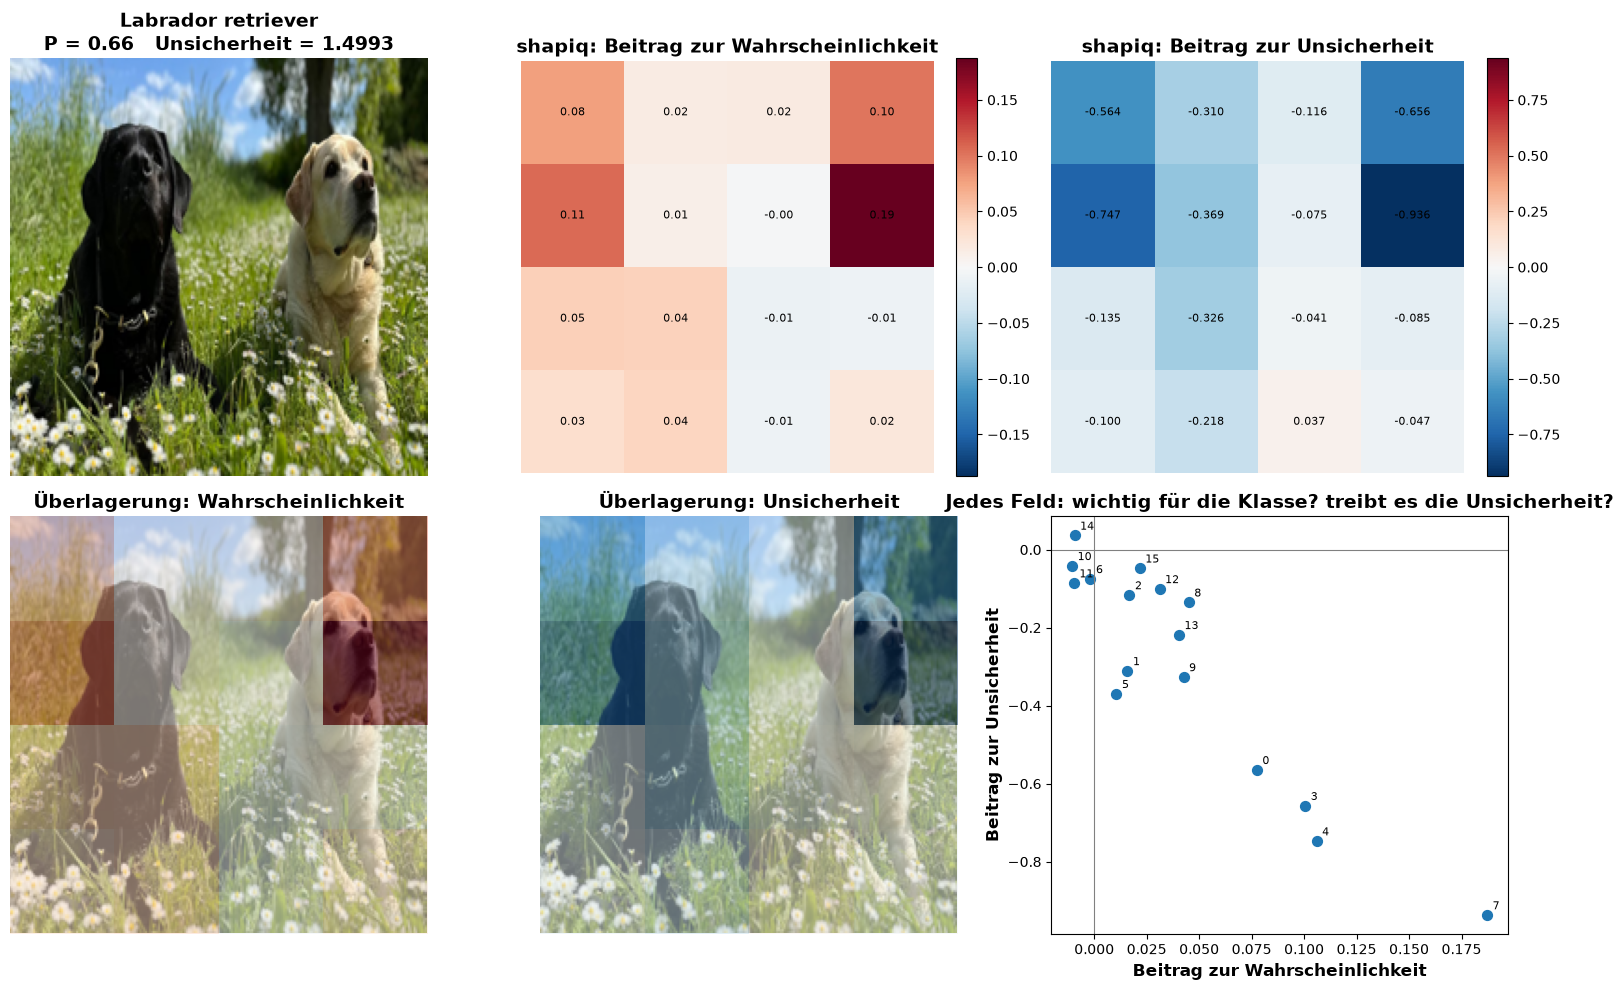


Wichtigstes Feld für die Klasse:           Feld 7  (+0.1872)
Feld mit größtem Beitrag zur Unsicherheit: Feld 14  (+0.03687)
Korrelation der beiden Beitragslisten:     -0.917


In [45]:
# ============================================================
# 0. EINSTELLUNGEN (hier alles Wichtige ändern)
# ============================================================
BILD_PFAD   = "b53d6916-f380-42a4-8d13-80daaa36492b.jpeg"    # z.B. "katze.jpg". None = Auswahl aus einer Liste der Bilder im Ordner
ZIEL_NAME   = None     # z.B. "tabby" oder "dog". None = wahrscheinlichste Klasse
N           = 4        # Raster N x N (3 = 9 Felder, 4 = 16 Felder)
NUM_SAMPLES = 5        # Dropout-Durchläufe pro Bildvariante (mehr = genauer, aber langsamer)
BUDGET      = 1024     # Anzahl Kombinationen bei der Näherung (nur bei mehr als 10 Feldern)

# ============================================================
# 1. Imports
# ============================================================
import os, glob, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.models import vgg16, VGG16_Weights
import shapiq
from shapiq.approximator import KernelSHAP
from probly.method import dropout
from probly.representer import representer
from probly.quantification import quantify

# import certifi; os.environ["SSL_CERT_FILE"] = certifi.where()   # nur falls Downloads am Mac scheitern

# ============================================================
# 2. Bild auswählen
# ============================================================
if BILD_PFAD is None:
    endungen = ("jpg", "jpeg", "png", "webp", "JPG", "JPEG", "PNG")
    liste = sorted(set(p for e in endungen for p in glob.glob(f"*.{e}")))
    if not liste:                                          # kein Bild im Ordner: Beispielhund laden
        urllib.request.urlretrieve("https://github.com/pytorch/hub/raw/master/images/dog.jpg", "bild.jpg")
        liste = ["bild.jpg"]
    print("Gefundene Bilder:")
    for i, p in enumerate(liste):
        print(f"  [{i}] {p}")
    eingabe = input(f"Nummer wählen (Enter = 0): ").strip()
    BILD_PFAD = liste[int(eingabe) if eingabe else 0]

print("Verwendetes Bild:", BILD_PFAD)
bild = Image.open(BILD_PFAD).convert("RGB")

# ============================================================
# 3. VGG16 laden, Bild vorbereiten, Zielklasse bestimmen
# ============================================================
gewichte = VGG16_Weights.IMAGENET1K_V1
vgg = vgg16(weights=gewichte).eval()
klassen = gewichte.meta["categories"]

x = gewichte.transforms()(bild).unsqueeze(0)               # (1, 3, 224, 224)
with torch.no_grad():
    wahrsch = torch.softmax(vgg(x), dim=1)[0]

top5 = torch.topk(wahrsch, 5)
print("\nTop 5 von VGG16:")
for p, i in zip(top5.values, top5.indices):
    print(f"  {int(i):4d}  {klassen[i]:28s} {p.item():.3f}")

if ZIEL_NAME is None:
    ziel = int(wahrsch.argmax())
else:
    treffer = [i for i, k in enumerate(klassen) if ZIEL_NAME.lower() in k.lower()]
    if not treffer:
        raise ValueError(f"Keine Klasse mit '{ZIEL_NAME}' gefunden")
    ziel = treffer[0]
print(f"\nErklärte Klasse: {klassen[ziel]}  (P = {wahrsch[ziel]:.3f})")

# ============================================================
# 4. Bild in N x N Felder teilen
# ============================================================
n_spieler = N * N
grenzen = np.linspace(0, 224, N + 1).astype(int)
feld_masken = []
for r in range(N):
    for c in range(N):
        m = torch.zeros(224, 224)
        m[grenzen[r]:grenzen[r + 1], grenzen[c]:grenzen[c + 1]] = 1
        feld_masken.append(m)
feld_masken = torch.stack(feld_masken)

# ============================================================
# 5. probly: Dropout-Modell
# ============================================================
mc  = dropout(vgg, p=0.2, predictor_type="logit_classifier")
rep = representer(mc, num_samples=NUM_SAMPLES)

def bewerte(koalitionen, batch=16):
    # pro Bildvariante: P(Zielklasse) und probly-Unsicherheit
    k = torch.tensor(koalitionen, dtype=torch.float32)
    ps, us = [], []
    for start in range(0, len(k), batch):
        teil = k[start:start + batch]
        maske = (teil[:, :, None, None] * feld_masken[None]).sum(1)
        bilder = x * maske[:, None]                         # verdeckte Felder = grau
        with torch.no_grad():
            sample = rep.represent(bilder)
            ps.append(sample.sample_mean().probabilities[:, ziel].detach().numpy())
            us.append(quantify(sample).total.detach().numpy())
    return np.concatenate(ps).astype(float), np.concatenate(us).astype(float)

# Zwischenspeicher: jede Kombination geht nur EINMAL durch VGG16
cache = {}
def hole(koal):
    keys = [tuple(bool(b) for b in z) for z in koal]
    fehlend = [k for k in dict.fromkeys(keys) if k not in cache]
    if fehlend:
        p, u = bewerte(np.array(fehlend))
        for k, pv, uv in zip(fehlend, p, u):
            cache[k] = (pv, uv)
    return keys

def spiel_p(koal): return np.array([cache[k][0] for k in hole(koal)], dtype=float)
def spiel_u(koal): return np.array([cache[k][1] for k in hole(koal)], dtype=float)

# ============================================================
# 6. shapiq: Beiträge der Felder (exakt bei bis zu 10 Feldern, sonst Näherung)
# ============================================================
def shapley(spiel):
    if n_spieler <= 10:
        sv = shapiq.ExactComputer(game=spiel, n_players=n_spieler)(index="SV", order=1)
    else:
        sv = KernelSHAP(n=n_spieler, random_state=0).approximate(budget=BUDGET, game=spiel)
    werte = np.array([sv.dict_values.get((i,), 0.0) for i in range(n_spieler)])
    return werte, sv.baseline_value

werte_p, basis_p = shapley(spiel_p)      # der langsame Teil
werte_u, basis_u = shapley(spiel_u)      # nutzt den Zwischenspeicher

voll = tuple([True] * n_spieler)
spiel_p(np.array([voll]))
P_voll, U_voll = cache[voll]

print("\n=== Beitrag zur WAHRSCHEINLICHKEIT ===")
print(np.round(werte_p.reshape(N, N), 3))
print(f"Basis {basis_p:.4f} + Summe {werte_p.sum():.4f} = {basis_p + werte_p.sum():.4f}   (ganzes Bild: {P_voll:.4f})")
print("\n=== Beitrag zur UNSICHERHEIT ===")
print(np.round(werte_u.reshape(N, N), 4))
print(f"Basis {basis_u:.5f} + Summe {werte_u.sum():.5f} = {basis_u + werte_u.sum():.5f}   (ganzes Bild: {U_voll:.5f})")

# ============================================================
# 7. Grafik
# ============================================================
karte_p, karte_u = werte_p.reshape(N, N), werte_u.reshape(N, N)
bild_224 = bild.resize((224, 224))
schrift = 8 if N > 3 else 10

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes[0, 0].imshow(bild_224); axes[0, 0].axis("off")
axes[0, 0].set_title(f"{klassen[ziel]}\nP = {P_voll:.2f}   Unsicherheit = {U_voll:.4f}")

for ax, karte, titel, fmt in [(axes[0, 1], karte_p, "shapiq: Beitrag zur Wahrscheinlichkeit", "{:.2f}"),
                              (axes[0, 2], karte_u, "shapiq: Beitrag zur Unsicherheit", "{:.3f}")]:
    g = np.abs(karte).max()
    im = ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g)
    for r in range(N):
        for c in range(N):
            ax.text(c, r, fmt.format(karte[r, c]), ha="center", va="center", fontsize=schrift)
    ax.set_title(titel); ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046)

for ax, karte, titel in [(axes[1, 0], karte_p, "Überlagerung: Wahrscheinlichkeit"),
                         (axes[1, 1], karte_u, "Überlagerung: Unsicherheit")]:
    g = np.abs(karte).max()
    ax.imshow(bild_224)
    ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g, alpha=0.5, extent=(0, 224, 224, 0), interpolation="nearest")
    ax.set_title(titel); ax.axis("off")

ax = axes[1, 2]
ax.scatter(werte_p, werte_u, s=50)
for i in range(n_spieler):
    ax.annotate(str(i), (werte_p[i], werte_u[i]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Beitrag zur Wahrscheinlichkeit"); ax.set_ylabel("Beitrag zur Unsicherheit")
ax.set_title("Jedes Feld: wichtig für die Klasse? treibt es die Unsicherheit?")
plt.tight_layout(); plt.show()

print(f"\nWichtigstes Feld für die Klasse:           Feld {int(np.argmax(werte_p))}  ({werte_p.max():+.4f})")
print(f"Feld mit größtem Beitrag zur Unsicherheit: Feld {int(np.argmax(werte_u))}  ({werte_u.max():+.5f})")
print(f"Korrelation der beiden Beitragslisten:     {np.corrcoef(werte_p, werte_u)[0, 1]:+.3f}")